In [2]:
import trident
%load_ext autoreload
%autoreload 2

2026-04-22 16:53:40,682 | INFO : names.dmp and nodes.dmp exist in /shares/swabseq/trident_globals, skipping download.


In [37]:
config = trident.tl.TridentConfig(
    reads="/shares/swabseq/tecan-lod1/0139101_F8_25110500714_S62_R1_001.fastq.gz",
    pair="/shares/swabseq/tecan-lod1/0139101_F8_25110500714_S62_R2_001.fastq.gz",
    library="/shares/swabseq/db/databases/metagenomic_data/11Mar2026-PathogenDB/clean.fna",
    database="/shares/swabseq/db/databases/metagenomic_data/11Mar2026-PathogenDB/",
    threads=30,
)
taxonomic_data = trident.tl.taxutils(config)
adata = trident.tl.load_adata(config, taxonomic_data)
display(adata)

2026-04-23 00:28:21,463 | INFO : Taxonomic reestimation data loading complete.


AnnData object with n_obs × n_vars = 2641420 × 300
    obs: 'read_id', 'kraken_label', 'reestimation', 'taxid_proba', 'read_cluster', 'read_cluster_color'
    var: 'taxid', 'L', 'sum_r(X_r,t)', 'composite_score', 'name', 'phi', 'pi', 'taxid_cluster', 'taxid_cluster_color', 'taxid_cluster_lca', 'marginal_proba'
    uns: 'trident'
    layers: 'probas'

train:   0%|          | 0/1000 [00:00<?, ?it/s]

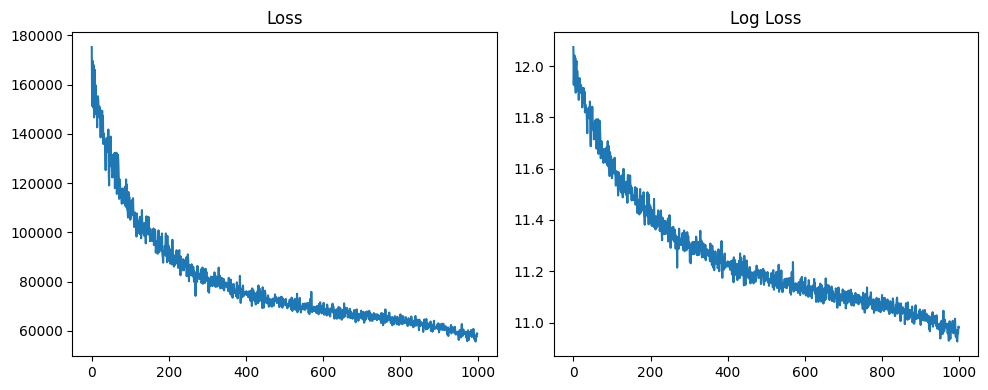

2026-04-14 18:23:39,150 | INFO : Saving trident model with run_id 0131403_A12_1_H1N1_D5_S89_R1_001-20260414-182339.
... storing 'kraken_label_name' as categorical
... storing 'reestimation_name' as categorical


In [154]:
trident.tl.train_trident(adata, config)

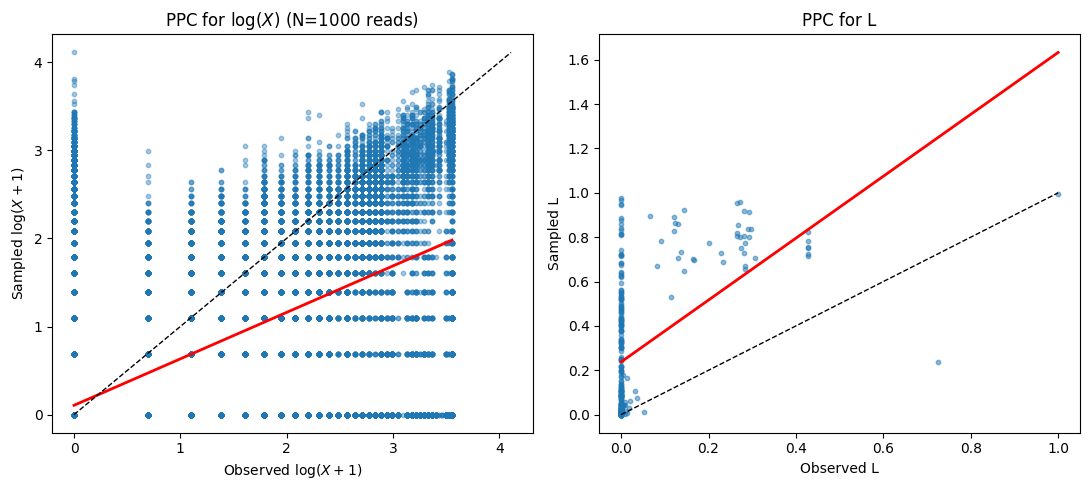

In [155]:
trident.pl.plot_ppc(adata)

2026-04-14 13:20:56,610 | INFO : Loaded model 0131403_C01_1_H3N2_D6_S3_R1_001-20260414-132047.


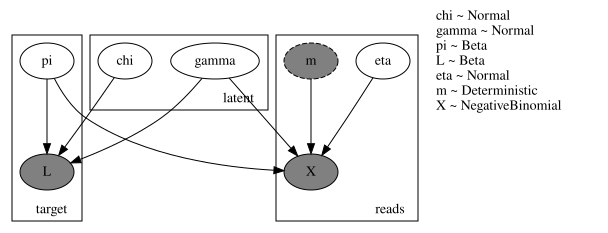

In [71]:
trident.pl.plate_model(adata, guide=False)

In [156]:
trident.tl.get_posteriors(adata, num_samples=1000)
trident.tl.var_marginal(adata)

2026-04-14 18:27:17,293 | INFO : Loaded model 0131403_A12_1_H1N1_D5_S89_R1_001-20260414-182339.
2026-04-14 18:27:17,326 | INFO : Overwriting existing trident model with run_id 0131403_A12_1_H1N1_D5_S89_R1_001-20260414-182339.
2026-04-14 18:27:21,265 | INFO : Added: `.var["pi"]`, `.var["phi"]`; cached posterior gamma on the model
2026-04-14 18:27:21,274 | INFO : Added `marginal_proba` to .var


2026-04-14 18:27:21,719 | INFO : Loaded model 0131403_A12_1_H1N1_D5_S89_R1_001-20260414-182339.
2026-04-14 18:27:21,753 | INFO : Overwriting existing trident model with run_id 0131403_A12_1_H1N1_D5_S89_R1_001-20260414-182339.
2026-04-14 18:27:25,749 | INFO : Added: `.var["pi"]`, `.var["phi"]`; cached posterior gamma on the model
2026-04-14 18:27:26,146 | INFO : Loaded model 0131403_A12_1_H1N1_D5_S89_R1_001-20260414-182339.
2026-04-14 18:27:26,610 | INFO : Added: `.var["taxid_cluster"]` and `.var["taxid_cluster_color"]`


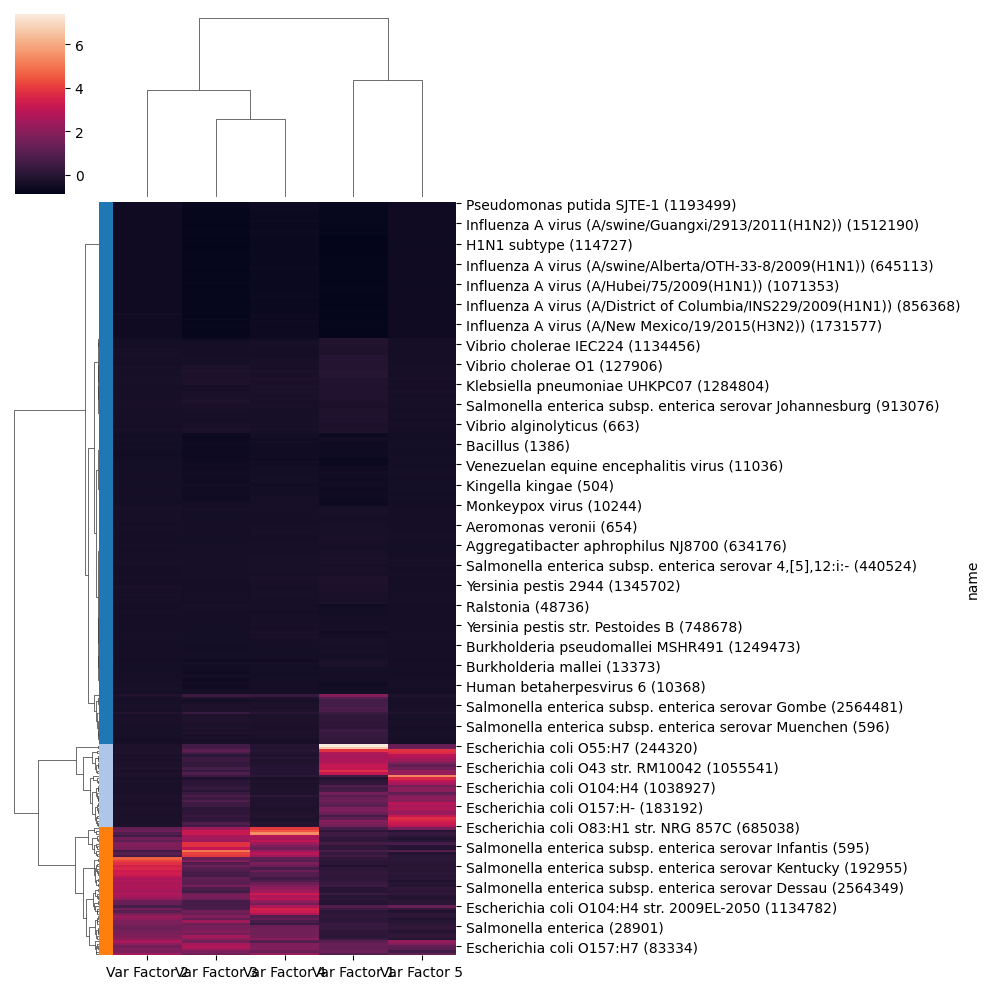

2026-04-14 18:27:29,014 | INFO : Added: `.var[taxid_cluster_lca]`
2026-04-14 18:27:29,554 | INFO : Loaded model 0131403_A12_1_H1N1_D5_S89_R1_001-20260414-182339.


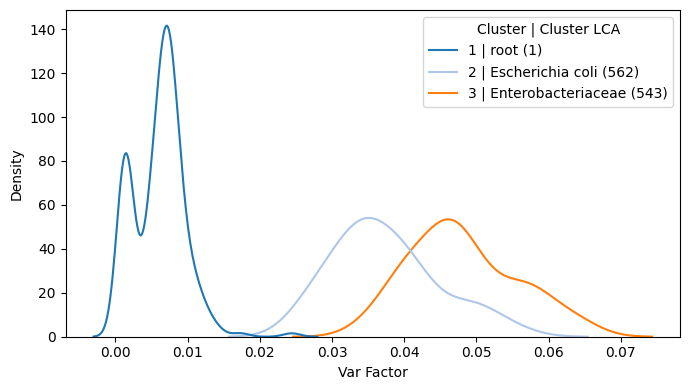

In [157]:
trident.tl.get_posteriors(adata, num_samples=1000)
trident.pl.var_cluster(
    adata, 
    method="ward", 
    standardize="zscore_cols", 
    mode="silhouette",
)
trident.tl.cluster_lca(adata, taxonomic_data)
trident.pl.var_factor_density(adata, taxonomic_data)

2026-04-23 00:28:22,454 | INFO : Added `reestimation` to .obs
2026-04-23 00:28:22,457 | INFO : Added `taxid_proba` to .obs
2026-04-23 00:28:22,787 | INFO : Added `marginal_proba` to .var
2026-04-23 00:28:38,797 | INFO : Added: `.obs["read_cluster"]` and `.obs["read_cluster_color"]`


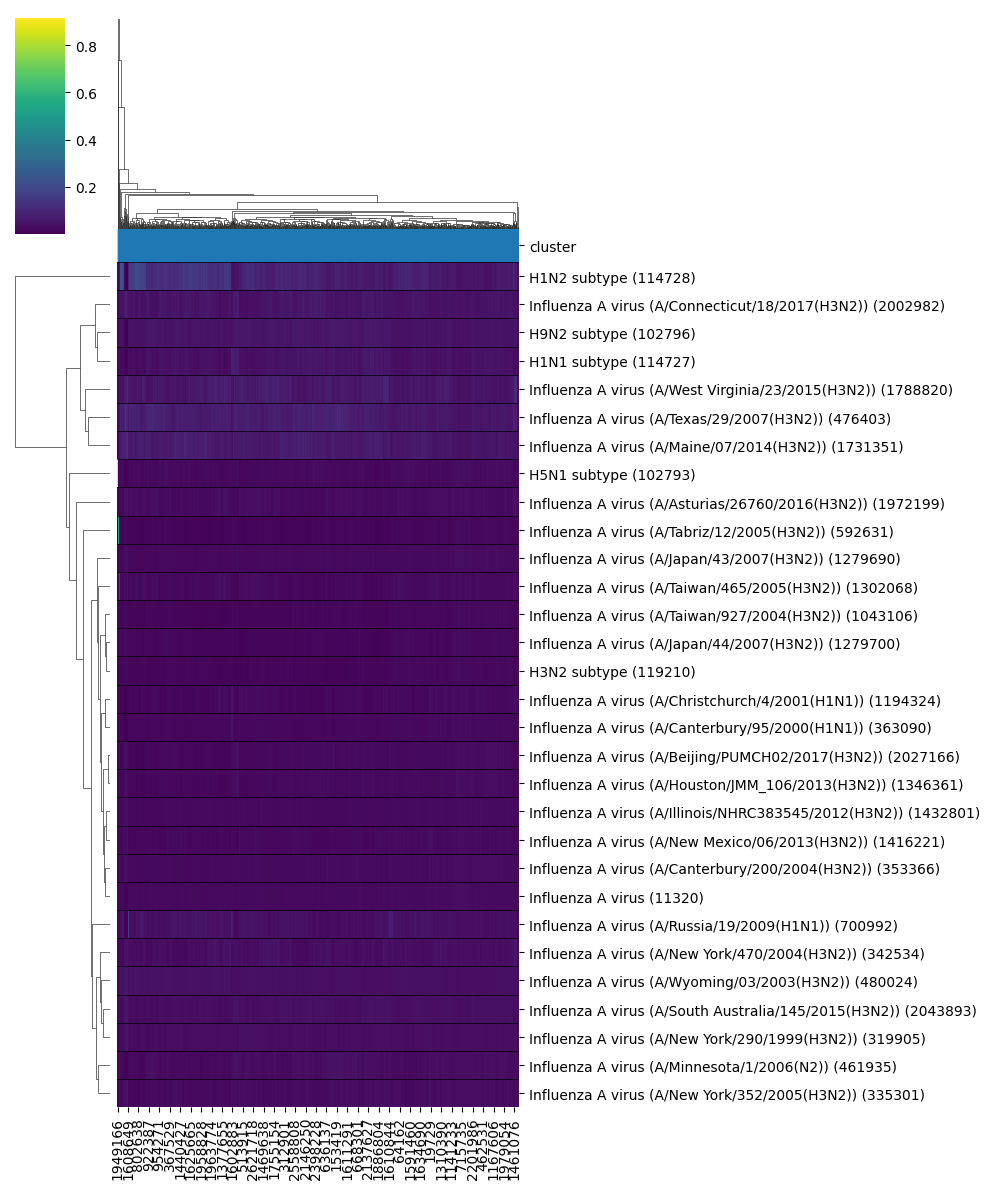

In [38]:
# probas = trident.tl._get_read_probabilities(adata)
trident.tl.reestimate(adata)
trident.tl.var_marginal(adata)
adata.obs["kraken_label_name"] = adata.obs["kraken_label"].map(taxonomic_data.names)
adata.obs["reestimation_name"] = adata.obs["reestimation"].map(taxonomic_data.names)
trident.pl.read_cluster(adata, n_reads_subsample=1000, top_n_var=30)

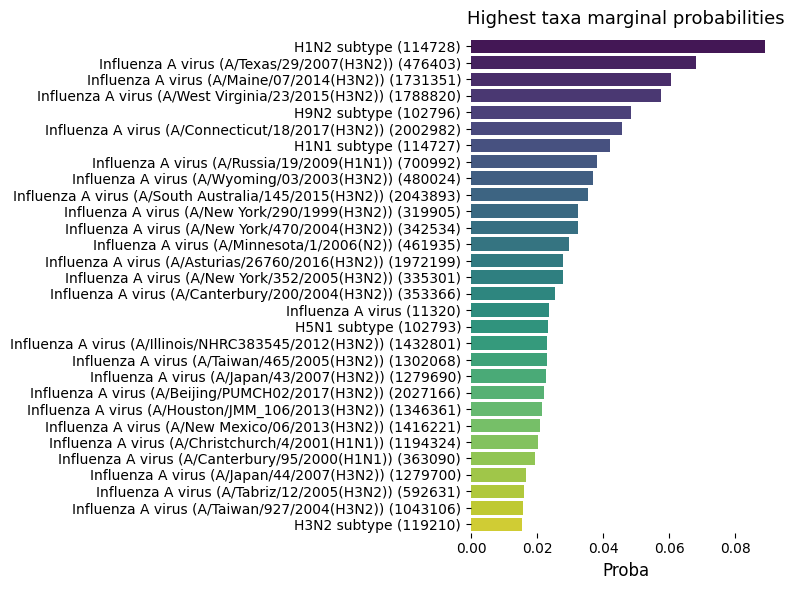

In [39]:
trident.pl.var_proba(adata, figsize=(8, 6), top_n=30)

In [1]:
trident.pl.transition(adata, figsize=(16, 12), top_n=5)
treport = trident.tl.to_treport(adata, taxonomic_data)
trident.pl.taxid_totals(adata, taxonomic_data)

NameError: name 'trident' is not defined

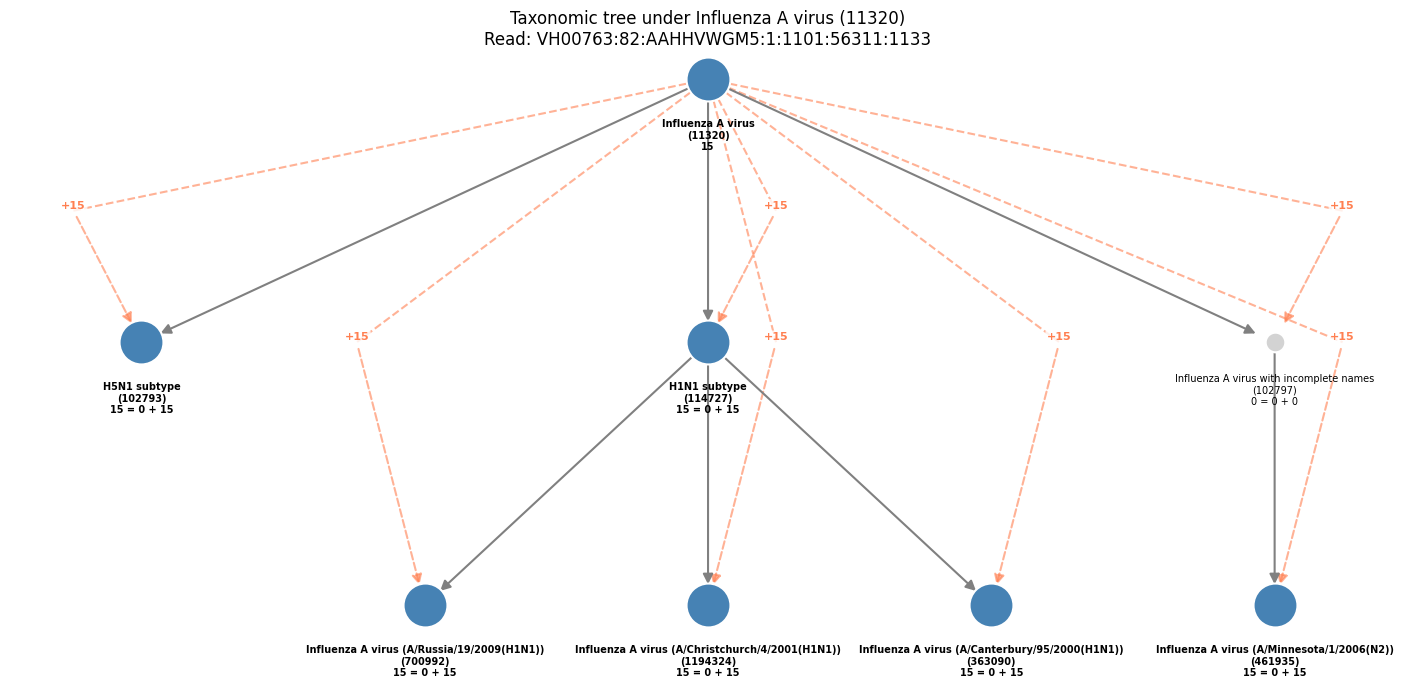

In [36]:
trident.pl.kmer_tree(
    adata,
    taxonomic_data,
    11320,
    [11320],
    top_n=5, save_path="figures/tree.png", read_cluster=2, row_idx=0, seed=0
)